# Customer Feedback Intelligence System

## Day 10 — Aspect-Level Sentiment Analysis

**Project Type:** Data Science, Machine Learning and Natural Language Processing (NLP)
**Domain:** Customer Analytics and Sentiment Analysis
**Task:** Identify sentiment for each aspect in customer feedback.

### Overview

This task focuses on identifying customer sentiment for specific product aspects such as quality, price, sound, bass, working, and delivery. The results will help understand which product features customers appreciate and which aspects may require improvement.


## 1. Objective

The objective of this task is to perform aspect-level sentiment analysis on customer feedback.

The aspects identified during Day 9 will be used to determine whether customer opinions about specific product aspects are Positive, Negative, or Neutral.

The analysis will generate aspect-level sentiment results and summaries that help identify customer satisfaction and areas requiring improvement.


In [7]:
import pandas as pd
import re
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Cleaned Dataset

The cleaned customer feedback dataset prepared in the previous tasks will be loaded for aspect-level sentiment analysis.

The dataset contains product names, prices, ratings, reviews, and summaries.


In [8]:
cleaned_file_path = r"C:\archive\Customer_Feedback_Cleaned.csv"

df = pd.read_csv(
    cleaned_file_path,
    encoding="utf-8"
)

print("Cleaned dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

Cleaned dataset loaded successfully!
Dataset Shape: (310789, 5)
Columns: ['Product_name', 'Price', 'Rate', 'Review', 'Summary']


## 3. Verify Dataset Columns

Before performing sentiment analysis, verify that the required columns are available.

The `Review`, `Summary`, and `Rate` columns will be used in this task.


In [9]:
required_columns = ["Review", "Summary", "Rate"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available.")

    display(df[required_columns].head(10))

All required columns are available.


,Review,Summary,Rate
0,simply awesome,really worth every single penny work like one ...,5
1,worth money desert cooler live name,bought crompton ozone desert air cooler month ...,4
2,worth every penny,great packaging seller important point transpo...,5
3,fabulous,delivery delayed two day except everything qui...,5
4,nice product,good cooler crompton height cooler ft inch col...,4
5,super,cant go wrong crompton brand punjab excellent ...,5
6,terrific purchase,great cooler great price compact great design ...,5
7,classy product,awesome product making fake comment bought tri...,5
8,perfect product,air throw goodlow noise best cooling medium sp...,5
9,cooler ac cooler,day using cooler room buying cooler love stron...,5


## 4. Create Overall Sentiment Labels

Customer ratings are used to assign an overall sentiment label to each review.

* **Rating 4–5:** Positive
* **Rating 3:** Neutral
* **Rating 1–2:** Negative

These labels represent the overall sentiment of a review. Aspect-level sentiment will be analyzed separately in the following steps.


In [10]:
def get_sentiment(rating):
    if pd.isna(rating):
        return "Neutral"
    elif rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["Sentiment"] = df["Rate"].apply(get_sentiment)

print("Overall sentiment labels created successfully!")

display(
    df[["Review", "Rate", "Sentiment"]].head(10)
)

print("\nOverall Sentiment Distribution:")
display(df["Sentiment"].value_counts().to_frame("Review_Count"))

Overall sentiment labels created successfully!


,Review,Rate,Sentiment
0,simply awesome,5,Positive
1,worth money desert cooler live name,4,Positive
2,worth every penny,5,Positive
3,fabulous,5,Positive
4,nice product,4,Positive
5,super,5,Positive
6,terrific purchase,5,Positive
7,classy product,5,Positive
8,perfect product,5,Positive
9,cooler ac cooler,5,Positive



Overall Sentiment Distribution:


,Review_Count
Sentiment,
Positive,232270
Negative,50286
Neutral,28233


## 5. Prepare Customer Feedback Text

The `Review` and `Summary` columns contain customer feedback.

Both columns will be combined into a single text column named `Combined_Text`. This will provide more text information for identifying aspects and analyzing their associated sentiment.


In [11]:
df["Combined_Text"] = (
    df["Review"].fillna("").astype(str)
    + " " 
    + df["Summary"].fillna("").astype(str)).str.strip()

print("Review and Summary combined successfully!")

display(
    df[["Review", "Summary", "Combined_Text"]].head(10)
)

Review and Summary combined successfully!


,Review,Summary,Combined_Text
0,simply awesome,really worth every single penny work like one ...,simply awesome really worth every single penny...
1,worth money desert cooler live name,bought crompton ozone desert air cooler month ...,worth money desert cooler live name bought cro...
2,worth every penny,great packaging seller important point transpo...,worth every penny great packaging seller impor...
3,fabulous,delivery delayed two day except everything qui...,fabulous delivery delayed two day except every...
4,nice product,good cooler crompton height cooler ft inch col...,nice product good cooler crompton height coole...
5,super,cant go wrong crompton brand punjab excellent ...,super cant go wrong crompton brand punjab exce...
6,terrific purchase,great cooler great price compact great design ...,terrific purchase great cooler great price com...
7,classy product,awesome product making fake comment bought tri...,classy product awesome product making fake com...
8,perfect product,air throw goodlow noise best cooling medium sp...,perfect product air throw goodlow noise best c...
9,cooler ac cooler,day using cooler room buying cooler love stron...,cooler ac cooler day using cooler room buying ...


## 6. Define Identified Aspects

The aspect keywords identified during Day 9 will be reused in this task.

The six aspects are Quality, Price, Sound, Bass, Working, and Delivery. Related keywords such as `money` and `value` are grouped under Price.

These predefined aspects will be used to identify customer feedback related to each product aspect.


In [12]:
aspect_dictionary = {
    "quality": ["quality"],
    "price": ["price", "money", "value"],
    "sound": ["sound"],
    "bass": ["bass"],
    "working": ["working"],
    "delivery": ["delivery"]
}

print("Aspect dictionary created successfully!")
print("Total aspects:", len(aspect_dictionary))

for aspect, keywords in aspect_dictionary.items():
    print(f"{aspect.title()}: {keywords}")

Aspect dictionary created successfully!
Total aspects: 6
Quality: ['quality']
Price: ['price', 'money', 'value']
Sound: ['sound']
Bass: ['bass']
Working: ['working']
Delivery: ['delivery']


## 7. Aspect Identification

Each customer feedback record will be checked for the predefined aspect keywords.

If a keyword is found in the combined feedback text, the corresponding aspect will be recorded. A review may contain more than one aspect.


In [14]:
def detect_aspects(text):
    text = str(text).lower()
    detected = []

    for aspect, keywords in aspect_dictionary.items():
        for keyword in keywords:
            pattern = rf"\b{re.escape(keyword)}\b"

            if re.search(pattern, text):
                detected.append(aspect)
                break

    return detected


df["Detected_Aspects"] = df["Combined_Text"].apply(detect_aspects)

print("Aspect identification completed successfully!")

display(
    df[["Combined_Text", "Detected_Aspects"]].head(15)
)

print("\nNumber of reviews containing each aspect:")

aspect_counts = {
    aspect: df["Detected_Aspects"].apply(
        lambda aspects: aspect in aspects
    ).sum()
    for aspect in aspect_dictionary
}

display(
    pd.DataFrame(
        list(aspect_counts.items()),
        columns=["Aspect", "Review_Count"]
    ).sort_values("Review_Count", ascending=False)
)

Aspect identification completed successfully!


,Combined_Text,Detected_Aspects
0,simply awesome really worth every single penny...,[]
1,worth money desert cooler live name bought cro...,"[quality, price]"
2,worth every penny great packaging seller impor...,[price]
3,fabulous delivery delayed two day except every...,[delivery]
4,nice product good cooler crompton height coole...,[]
5,super cant go wrong crompton brand punjab exce...,[quality]
6,terrific purchase great cooler great price com...,"[price, delivery]"
7,classy product awesome product making fake com...,[]
8,perfect product air throw goodlow noise best c...,[]
9,cooler ac cooler day using cooler room buying ...,[]



Number of reviews containing each aspect:


,Aspect,Review_Count
0,quality,45133
1,price,39226
2,sound,20807
4,working,10069
3,bass,10061
5,delivery,6895


## 8. Aspect-Level Sentiment Analysis

In this step, sentiment will be identified separately for each detected aspect.

Positive and negative opinion words near an aspect keyword will be used to estimate the sentiment associated with that aspect.

* Positive sentiment indicates favorable feedback.
* Negative sentiment indicates unfavorable feedback.
* Neutral sentiment indicates that no clear positive or negative opinion is detected.

This is a rule-based baseline and may not correctly interpret every sentence or complex negation.


In [15]:
positive_words = {
    "good", "great", "excellent", "awesome", "best",
    "nice", "perfect", "wonderful", "amazing", "super",
    "brilliant", "fantastic", "satisfied", "smooth",
    "clear", "fast", "worth", "durable", "beautiful",
    "love", "happy"
}

negative_words = {
    "bad", "poor", "worst", "waste", "terrible",
    "awful", "disappointing", "disappointed", "defective",
    "slow", "issue", "problem", "broken", "faulty",
    "weak", "useless", "damaged", "noisy", "overheating"
}

print("Positive sentiment words:", len(positive_words))
print("Negative sentiment words:", len(negative_words))

Positive sentiment words: 21
Negative sentiment words: 19


## 9. Define the Aspect Sentiment Function

A function will examine the words around an aspect keyword and calculate a sentiment score.

A positive score indicates Positive sentiment, a negative score indicates Negative sentiment, and a zero score indicates Neutral sentiment.


In [23]:
def sentiment_near_aspect(text, keywords, window=1):
    tokens = re.findall(r"\b[a-z]+\b", str(text).lower())
    scores = []

    for i, token in enumerate(tokens):
        if token not in keywords:
            continue

        start = max(0, i - window)
        end = min(len(tokens), i + window + 1)
        context = tokens[start:end]

        score = sum(
            1 for word in context if word in positive_words
        ) - sum(
            1 for word in context if word in negative_words
        )

        scores.append(score)

    if not scores:
        return None

    total_score = sum(scores)

    if total_score > 0:
        return "Positive"
    elif total_score < 0:
        return "Negative"
    else:
        return "Neutral"


print("Aspect sentiment function updated successfully!")

Aspect sentiment function updated successfully!


In [24]:
example_text = "good sound and poor quality"

print("Sound:", sentiment_near_aspect(example_text, ["sound"]))
print("Quality:", sentiment_near_aspect(example_text, ["quality"]))

Sound: Positive
Quality: Negative


## 10. Generate Aspect-Level Sentiment Results

The sentiment function will be applied to the customer feedback records.

For each detected aspect, the system will estimate its sentiment and store the aspect, sentiment, review text, and rating in a results table.

These records will be used to prepare aspect-level sentiment summaries.


In [25]:
aspect_sentiment_records = []

for _, row in df.iterrows():
    text = str(row["Combined_Text"])
    detected_aspects = row["Detected_Aspects"]

    for aspect in detected_aspects:
        sentiment = sentiment_near_aspect(
            text,
            aspect_dictionary[aspect]
        )

        if sentiment is not None:
            aspect_sentiment_records.append({
                "Aspect": aspect,
                "Sentiment": sentiment,
                "Review": text,
                "Rate": row["Rate"]
            })

aspect_sentiment_df = pd.DataFrame(aspect_sentiment_records)

print("Aspect sentiment records generated successfully!")
print("Total aspect-level records:", len(aspect_sentiment_df))

display(aspect_sentiment_df.head(10))

Aspect sentiment records generated successfully!
Total aspect-level records: 132191


,Aspect,Sentiment,Review,Rate
0,quality,Neutral,worth money desert cooler live name bought cro...,4
1,price,Positive,worth money desert cooler live name bought cro...,4
2,price,Neutral,worth every penny great packaging seller impor...,5
3,delivery,Neutral,fabulous delivery delayed two day except every...,5
4,quality,Neutral,super cant go wrong crompton brand punjab exce...,5
5,price,Positive,terrific purchase great cooler great price com...,5
6,delivery,Neutral,terrific purchase great cooler great price com...,5
7,quality,Positive,wonderful good quality product better expectat...,5
8,price,Positive,wonderful good quality product better expectat...,5
9,delivery,Neutral,ok kind coolernot effective hot condition deli...,3


## 11. Summarize Sentiment by Aspect

The aspect-level sentiment records will be grouped by aspect and sentiment.

The summary will show the number of Positive, Negative, and Neutral results for each aspect. This will help compare customer opinions about different product aspects.


In [28]:
aspect_sentiment_summary = (
    aspect_sentiment_df
    .groupby(["Aspect", "Sentiment"])
    .size()
    .unstack(fill_value=0)
)


for sentiment in ["Positive", "Negative", "Neutral"]:
    if sentiment not in aspect_sentiment_summary.columns:
        aspect_sentiment_summary[sentiment] = 0


aspect_sentiment_summary = aspect_sentiment_summary[
    ["Positive", "Negative", "Neutral"]
]

print("Aspect-level sentiment summary created successfully!")

display(aspect_sentiment_summary)

Aspect-level sentiment summary created successfully!


Sentiment,Positive,Negative,Neutral
Aspect,,,
bass,4569,238,5254
delivery,2743,173,3979
price,15190,7501,16535
quality,24224,6649,14260
sound,9784,727,10296
working,2261,458,7350


## 12. Aspect-Level Sentiment Visualization

A grouped bar chart will be created to compare Positive, Negative, and Neutral sentiment results across the six aspects.

The chart will make it easier to compare sentiment patterns for different product aspects.


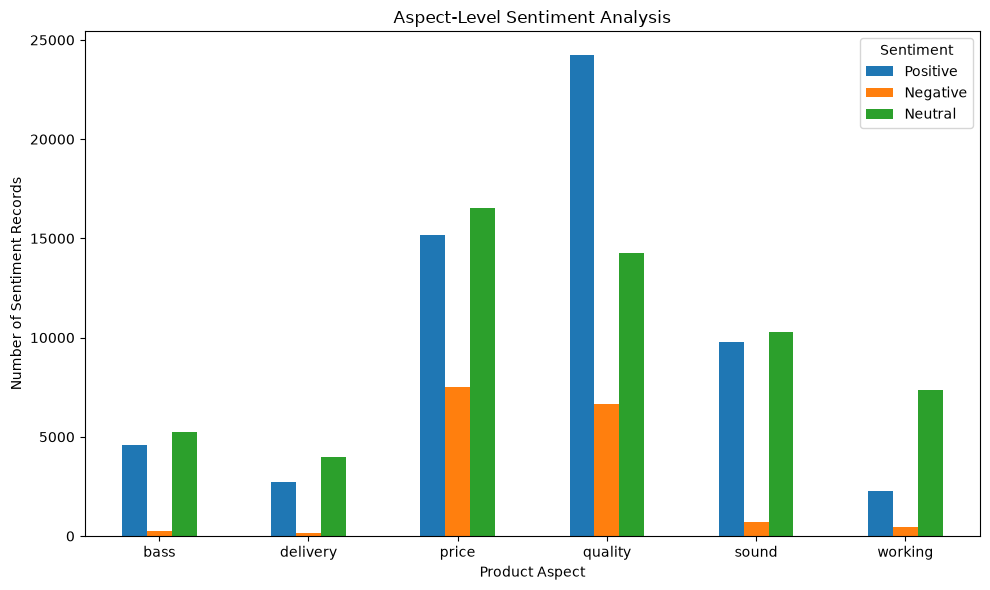

In [29]:
aspect_sentiment_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Aspect-Level Sentiment Analysis")
plt.xlabel("Product Aspect")
plt.ylabel("Number of Sentiment Records")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

## 13. Analyze Aspect-Level Sentiment Insights

In this section, we analyze the sentiment summary for each product aspect. We identify the aspects with the highest positive and negative sentiment counts.

These results are based on a rule-based sentiment analysis method and should be interpreted as preliminary estimates.


In [30]:


most_positive_aspect = aspect_sentiment_summary["Positive"].idxmax()
most_negative_aspect = aspect_sentiment_summary["Negative"].idxmax()

print("Aspect with the highest positive sentiment count:")
print(
    most_positive_aspect.title(),
    "-",
    aspect_sentiment_summary.loc[most_positive_aspect, "Positive"]
)

print("\nAspect with the highest negative sentiment count:")
print(
    most_negative_aspect.title(),
    "-",
    aspect_sentiment_summary.loc[most_negative_aspect, "Negative"]
)

print("\nComplete Aspect-Level Sentiment Summary:")
display(aspect_sentiment_summary)

Aspect with the highest positive sentiment count:
Quality - 24224

Aspect with the highest negative sentiment count:
Price - 7501

Complete Aspect-Level Sentiment Summary:


Sentiment,Positive,Negative,Neutral
Aspect,,,
bass,4569,238,5254
delivery,2743,173,3979
price,15190,7501,16535
quality,24224,6649,14260
sound,9784,727,10296
working,2261,458,7350


## 14. Save Aspect-Level Sentiment Results

In this section, we save the aspect-level sentiment records and summary into separate CSV files for further analysis and reporting. The original cleaned dataset will remain unchanged.


In [31]:

aspect_sentiment_df.to_csv(
    r"C:\archive\Aspect_Sentiment_Records.csv",
    index=False,
    encoding="utf-8-sig"
)


aspect_sentiment_summary.to_csv(
    r"C:\archive\Aspect_Sentiment_Summary.csv",
    encoding="utf-8-sig"
)

print("Aspect-level sentiment results saved successfully!")
print("Detailed records: C:\\archive\\Aspect_Sentiment_Records.csv")
print("Summary: C:\\archive\\Aspect_Sentiment_Summary.csv")

Aspect-level sentiment results saved successfully!
Detailed records: C:\archive\Aspect_Sentiment_Records.csv
Summary: C:\archive\Aspect_Sentiment_Summary.csv


## 15. Key Findings

The aspect-level sentiment analysis produced the following findings:

* **Quality:** Recorded the highest positive sentiment count, with 24,224 records.
* **Price:** Recorded the highest negative sentiment count, with 7,501 records.
* **Sound:** Recorded 9,784 positive sentiment records.
* **Delivery:** Recorded 173 negative sentiment records.
* **Working:** Recorded 2,261 positive sentiment records.

These findings are based on a rule-based sentiment analysis approach. The counts represent estimated sentiment labels, not verified customer opinions.


## 16. Conclusion

In this task, aspect-level sentiment analysis was performed on customer feedback. Six product aspects—Quality, Price, Sound, Bass, Working, and Delivery—were identified and analyzed.

A rule-based function using positive and negative opinion words was applied to estimate the sentiment associated with each aspect. The results were summarized and visualized, and the detailed records and summary were saved as CSV files.

This analysis provides an initial understanding of customer feedback. However, the rule-based method has limitations and may not correctly interpret every review. A more advanced NLP or machine learning model could be explored to improve sentiment classification.
